# Project Foundations for Data Science: FoodHub Data Analysis

**Marks: 60**

### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business. 

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [155]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [156]:
# read the data
df = pd.read_csv('data\\raw\\foodhub_order.csv')
# returns the first 5 rows
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


#### Observations:

The DataFrame has 9 columns as mentioned in the Data Dictionary. Data in each row corresponds to the order placed by a customer.

### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [157]:
# check the shape of the dataset
df.shape

(1898, 9)

#### Observations:

The dataset contains 1,898 rows and 9 columns. Each row represents one food order placed through the FoodHub platform, and the columns capture customer, restaurant, order cost, timing, and rating information.

### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [158]:
# Use info() to print a concise summary of the DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   str    
 3   cuisine_type           1898 non-null   str    
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   str    
 6   rating                 1898 non-null   str    
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), str(4)
memory usage: 133.6 KB


#### Observations:

The dataset contains a mix of numerical and categorical variables. The columns `order_id`, `customer_id`, `cost_of_the_order`, `food_preparation_time`, and `delivery_time` are numeric, while `restaurant_name`, `cuisine_type`, `day_of_the_week`, and `rating` are stored as object data types. The object columns represent categorical information, and the ID columns should be treated as identifiers rather than continuous numerical variables.

### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [159]:
# Display any missing values in the dataset
df.isnull().sum()

order_id                 0
customer_id              0
restaurant_name          0
cuisine_type             0
cost_of_the_order        0
day_of_the_week          0
rating                   0
food_preparation_time    0
delivery_time            0
dtype: int64

#### Observations:

There are no missing values in the dataset, so no imputation or row removal is required. However, the `rating` column contains the value `Not given` for orders that were not rated. This is not a null value, but it should be treated carefully during analysis because it represents missing customer feedback rather than an actual rating.

### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [160]:
# Check the statistical summary of the data using .describe()
# using .loc to display minimum, average, and maximum time it takes for food to be prepared once an order is placed
df['food_preparation_time'].describe().loc[['min', 'max', 'mean']]
#Print the minimum, maximum, and average food preparation time
print(f"Minimum food preparation time: {df['food_preparation_time'].min()} minutes")
print(f"Maximum food preparation time: {df['food_preparation_time'].max()} minutes")
print(f"Average food preparation time: {df['food_preparation_time'].mean():.2f} minutes")


Minimum food preparation time: 20 minutes
Maximum food preparation time: 35 minutes
Average food preparation time: 27.37 minutes


#### Observations:

The minimum food preparation time is 20 minutes, the average is about 27.37 minutes, and the maximum is 35 minutes. This suggests that preparation times are fairly concentrated within a relatively narrow range, with no extreme variation across orders.

### **Question 5:** How many orders are not rated? [1 mark]

In [161]:
# Display the total count of orders that are not rated
count_nr = (df['rating'] == 'Not given').sum() #count the number of orders that are not rated
print(f"The total count of orders that are not rated: {count_nr}") #Print the total count of orders that are not rated


The total count of orders that are not rated: 736


#### Observations:

There are 736 orders that are not rated. This is a substantial portion of the dataset, so any analysis involving customer satisfaction or ratings should take into account that feedback is incomplete.

### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,1898.0,NaN,NaN,NaN,1477495.5,548.049724,1476547.0,1477021.25,1477495.5,1477969.75,1478444.0
customer_id,1898.0,NaN,NaN,NaN,171168.478398,113698.139743,1311.0,77787.75,128600.0,270525.0,405334.0
restaurant_name,1898,178,Shake Shack,219,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cuisine_type,1898,14,American,584,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cost_of_the_order,1898.0,NaN,NaN,NaN,16.498851,7.483812,4.47,12.08,14.14,22.2975,35.41
day_of_the_week,1898,2,Weekend,1351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,1898,4,Not given,736,NaN,NaN,NaN,NaN,NaN,NaN,NaN
food_preparation_time,1898.0,NaN,NaN,NaN,27.37197,4.632481,20.0,23.0,27.0,31.0,35.0
delivery_time,1898.0,NaN,NaN,NaN,24.161749,4.972637,15.0,20.0,25.0,28.0,33.0


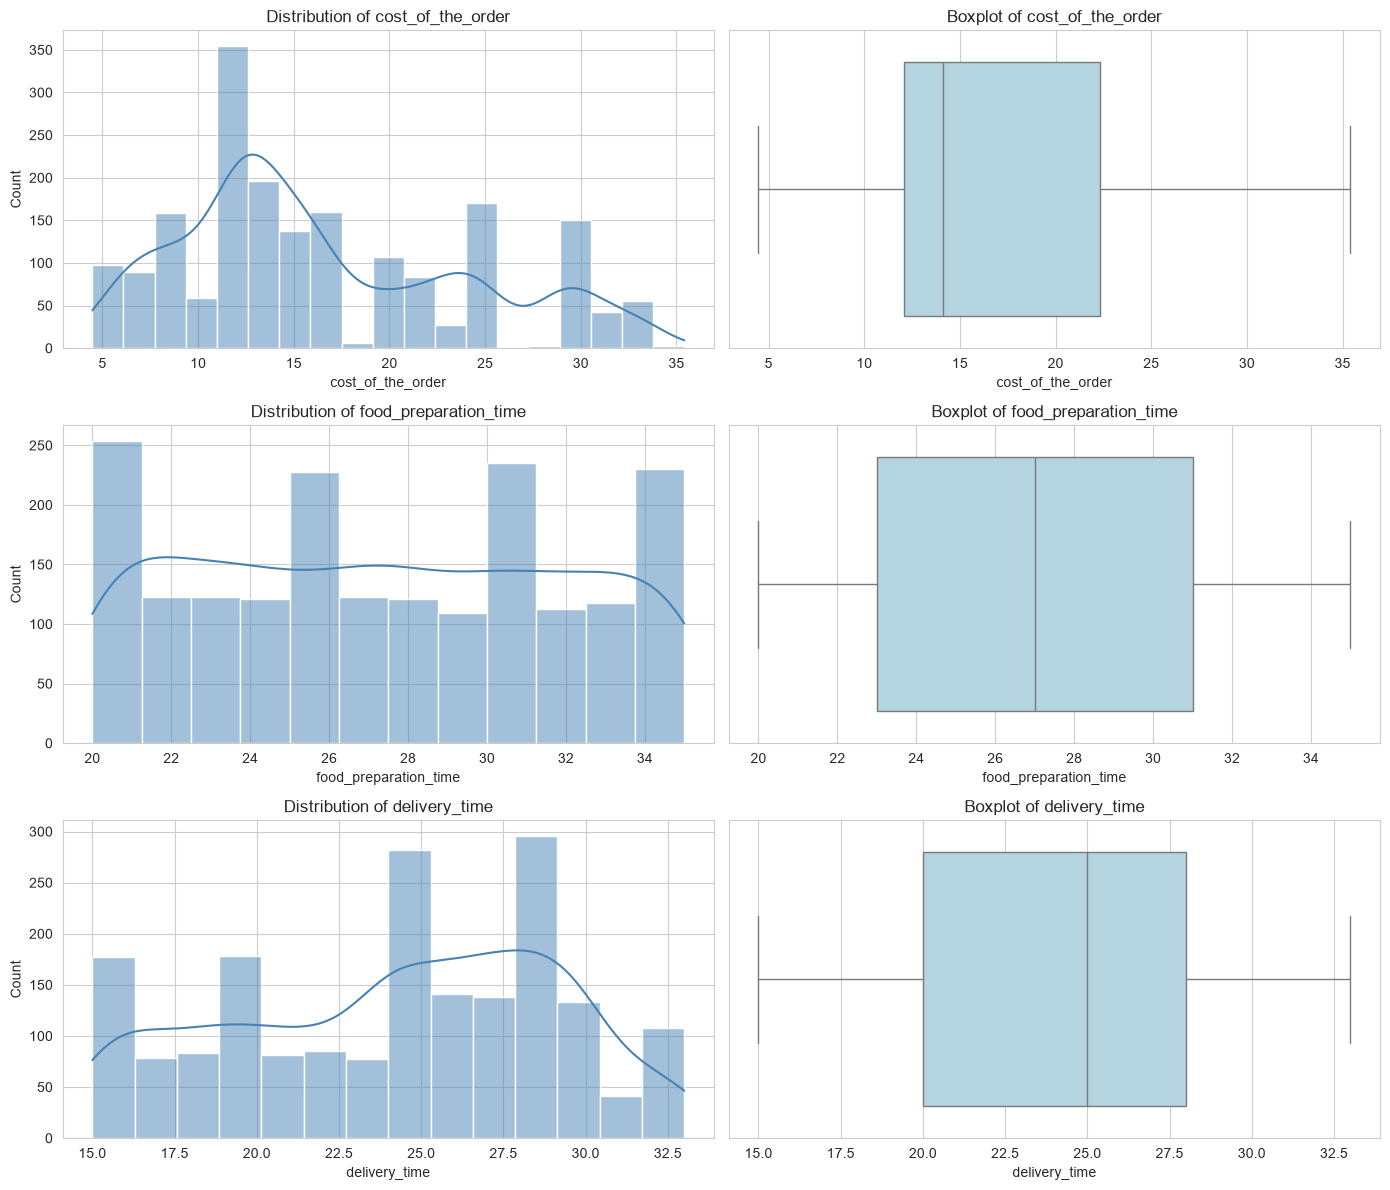

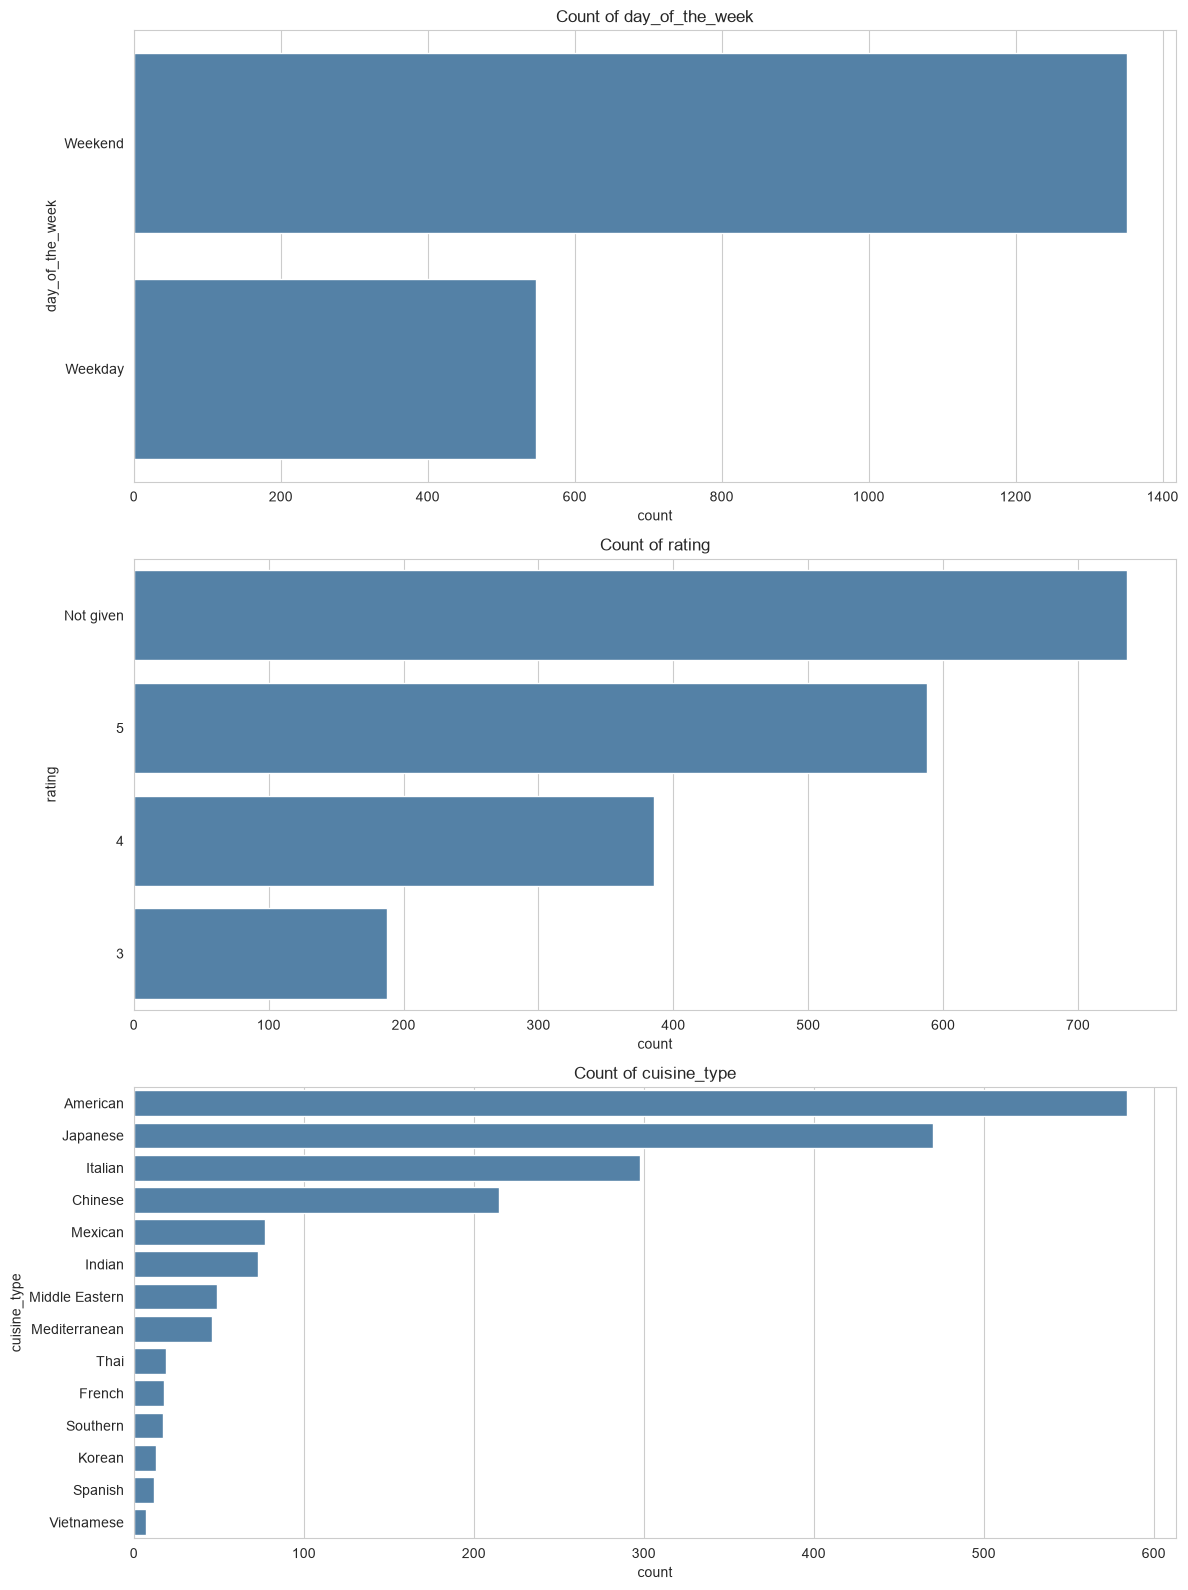

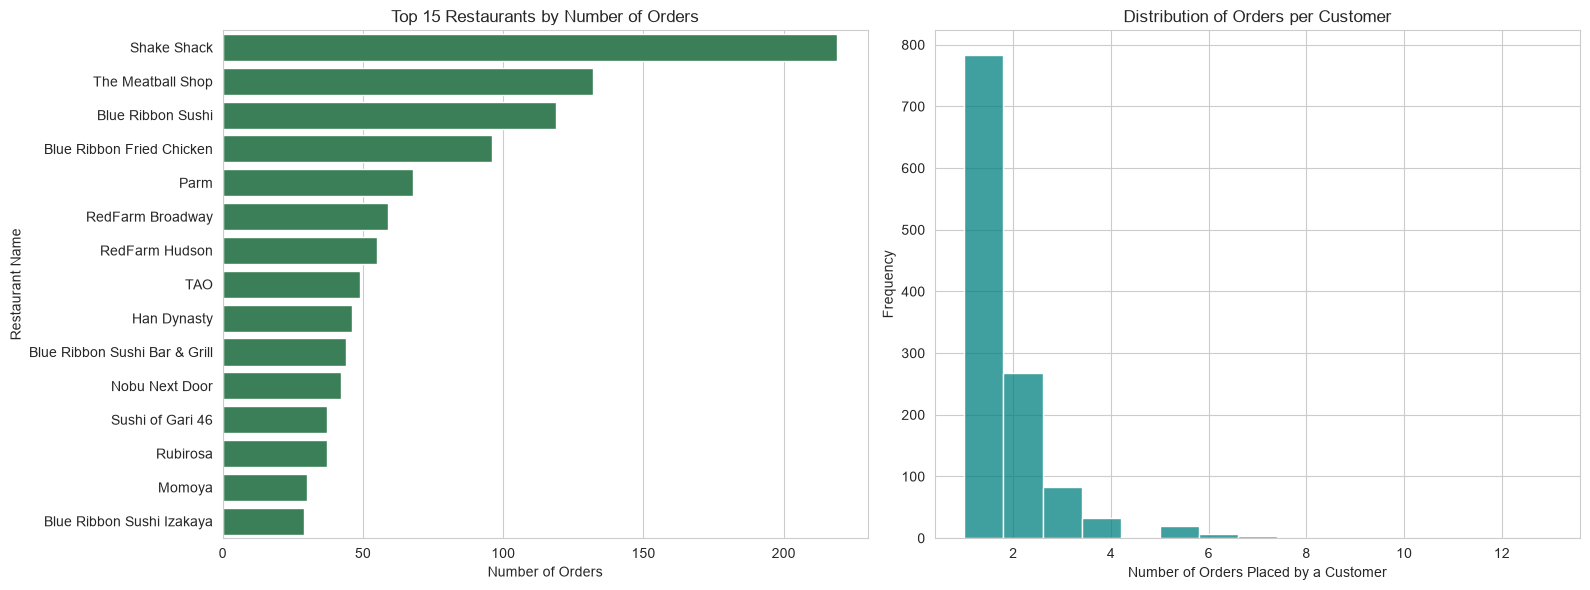

Observations:
- Cost of orders is concentrated in the lower to middle price range, with a few higher-value orders.
- Food preparation time and delivery time show moderate spread and no extreme outliers.
- More orders are placed on weekends than weekdays.
- 'Not given' is the most common value in ratings, indicating many unrated orders.
- American, Japanese, Italian, and Chinese cuisines account for most orders.
- Restaurant demand is concentrated among a small number of restaurants, while most customers place only a few orders.


In [162]:
# Univariate analysis
sns.set_style('whitegrid')

# Summary table
display(df.describe(include='all').T)

# Numerical variables
num_cols = ['cost_of_the_order', 'food_preparation_time', 'delivery_time']

fig, axes = plt.subplots(len(num_cols), 2, figsize=(14, 12)) # Create subplots for each numerical column

for i, col in enumerate(num_cols): #for loop to iterate through the numerical columns and create histograms and boxplots
    sns.histplot(data=df, x=col, kde=True, ax=axes[i, 0], color='steelblue') # Create histogram
    axes[i, 0].set_title(f'Distribution of {col}') # Set title for histogram
    
    sns.boxplot(data=df, x=col, ax=axes[i, 1], color='lightblue') # Create boxplot
    axes[i, 1].set_title(f'Boxplot of {col}') # Set title for boxplot

plt.tight_layout() # Adjust the layout to prevent overlap
plt.show() # Display the plots

# Categorical variables with manageable cardinality
cat_cols = ['day_of_the_week', 'rating', 'cuisine_type']

fig, axes = plt.subplots(len(cat_cols), 1, figsize=(12, 16)) # Create subplots for each categorical column

for i, col in enumerate(cat_cols): # for loop to iterate through the categorical columns and create countplots
    order = df[col].value_counts().index # Get the order of categories based on their counts
    sns.countplot(data=df, y=col, order=order, ax=axes[i], color='steelblue') # Create countplot
    axes[i].set_title(f'Count of {col}') # Set title for countplot

plt.tight_layout() # Adjust the layout to prevent overlap
plt.show() # Display the plots

# High-cardinality variables
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

restaurant_order = df['restaurant_name'].value_counts().head(15) # Get the top 15 restaurants by number of orders
sns.barplot(x=restaurant_order.values, y=restaurant_order.index, ax=axes[0], color='seagreen') # Create barplot for top 15 restaurants by number of orders
axes[0].set_title('Top 15 Restaurants by Number of Orders') # Set title for barplot
axes[0].set_xlabel('Number of Orders') # Set x-axis label for barplot
axes[0].set_ylabel('Restaurant Name') # Set y-axis label for barplot

customer_order_counts = df['customer_id'].value_counts() # Get the number of orders placed by each customer
sns.histplot(customer_order_counts, bins=15, ax=axes[1], color='teal') # Create histogram for distribution of orders per customer
axes[1].set_title('Distribution of Orders per Customer') # Set title for histogram
axes[1].set_xlabel('Number of Orders Placed by a Customer') # Set x-axis label for histogram
axes[1].set_ylabel('Frequency') # Set y-axis label for histogram

plt.tight_layout() # Adjust the layout to prevent overlap
plt.show() # Display the plots

# Brief observations
print('Observations:')
print('- Cost of orders is concentrated in the lower to middle price range, with a few higher-value orders.')
print('- Food preparation time and delivery time show moderate spread and no extreme outliers.')
print('- More orders are placed on weekends than weekdays.')
print("- 'Not given' is the most common value in ratings, indicating many unrated orders.")
print('- American, Japanese, Italian, and Chinese cuisines account for most orders.')
print('- Restaurant demand is concentrated among a small number of restaurants, while most customers place only a few orders.')


### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [163]:
# Top 5 restaurants by number of orders received
df['restaurant_name'].value_counts().head(5)
#print the top 5 restaurants by number of orders received
print("Top 5 restaurants by number of orders received:")
for restaurant, count in df['restaurant_name'].value_counts().head(5).items(): #for loop to iterate through the top 5 restaurants and their order counts
    print(f"{restaurant}: {count} orders")


Top 5 restaurants by number of orders received:
Shake Shack: 219 orders
The Meatball Shop: 132 orders
Blue Ribbon Sushi: 119 orders
Blue Ribbon Fried Chicken: 96 orders
Parm: 68 orders


#### Observations:

The top 5 restaurants by number of orders are Shake Shack, The Meatball Shop, Blue Ribbon Sushi, Blue Ribbon Fried Chicken, and Parm. This indicates that customer demand is concentrated among a relatively small group of restaurants, which could be important for partnership and promotional strategy.

### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

In [164]:
# Most popular cuisine on weekends
pop_cuisine = df[df['day_of_the_week'] == 'Weekend']['cuisine_type'].value_counts().head(1)
print(f"The most popular cuisine on weekends is: {pop_cuisine.index[0]} with {pop_cuisine.values[0]} orders.")

The most popular cuisine on weekends is: American with 415 orders.


#### Observations:

American cuisine is the most popular on weekends, with 415 orders. This suggests that customer demand for American food is especially strong during weekends, which could help guide weekend promotions, restaurant partnerships, and delivery planning.

### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [165]:
# Percentage of orders costing more than 20 dollars
percentage = round((df[df['cost_of_the_order'] > 20].shape[0] / df.shape[0]) * 100, 2)
print(f"Percentage of orders costing more than 20 dollars: {percentage}%")


Percentage of orders costing more than 20 dollars: 29.24%


#### Observations:

About 29.24% of the orders cost more than 20 dollars. This indicates that a meaningful share of orders falls into a higher-value segment, which can contribute more strongly to revenue and commission generation.

### **Question 10**: What is the mean order delivery time? [1 mark]

In [166]:
# Mean order delivery time
mean_delivery_time = round(df['delivery_time'].mean(), 2)
print(f"Mean order delivery time: {mean_delivery_time} minutes")


Mean order delivery time: 24.16 minutes


#### Observations:

The mean delivery time is 24.16 minutes. This suggests that, on average, the delivery process takes about 24 minutes after the food is picked up, which can serve as a useful benchmark for evaluating delivery efficiency.

### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [167]:
# Find the IDs of the top 3 most frequent customers and the number of orders they placed.
print("Top 3 most frequent customers and the number of orders they placed:")
top_customers = df['customer_id'].value_counts().head(3) # Get the top 3 most frequent customers and their order counts
for customer_id, order_count in top_customers.items(): #for loop to iterate through the top 3 most frequent customers and their order counts
    print(f"Customer ID: {customer_id}, Orders: {order_count}")

Top 3 most frequent customers and the number of orders they placed:
Customer ID: 52832, Orders: 13
Customer ID: 47440, Orders: 10
Customer ID: 83287, Orders: 9


#### Observations:

The top 3 most frequent customers place noticeably more orders than the average customer, which indicates the presence of a valuable repeat-customer segment. Offering vouchers to these customers is a sensible retention strategy that could help strengthen loyalty and encourage continued ordering.

### **Question 12a:** Bivariate Analysis


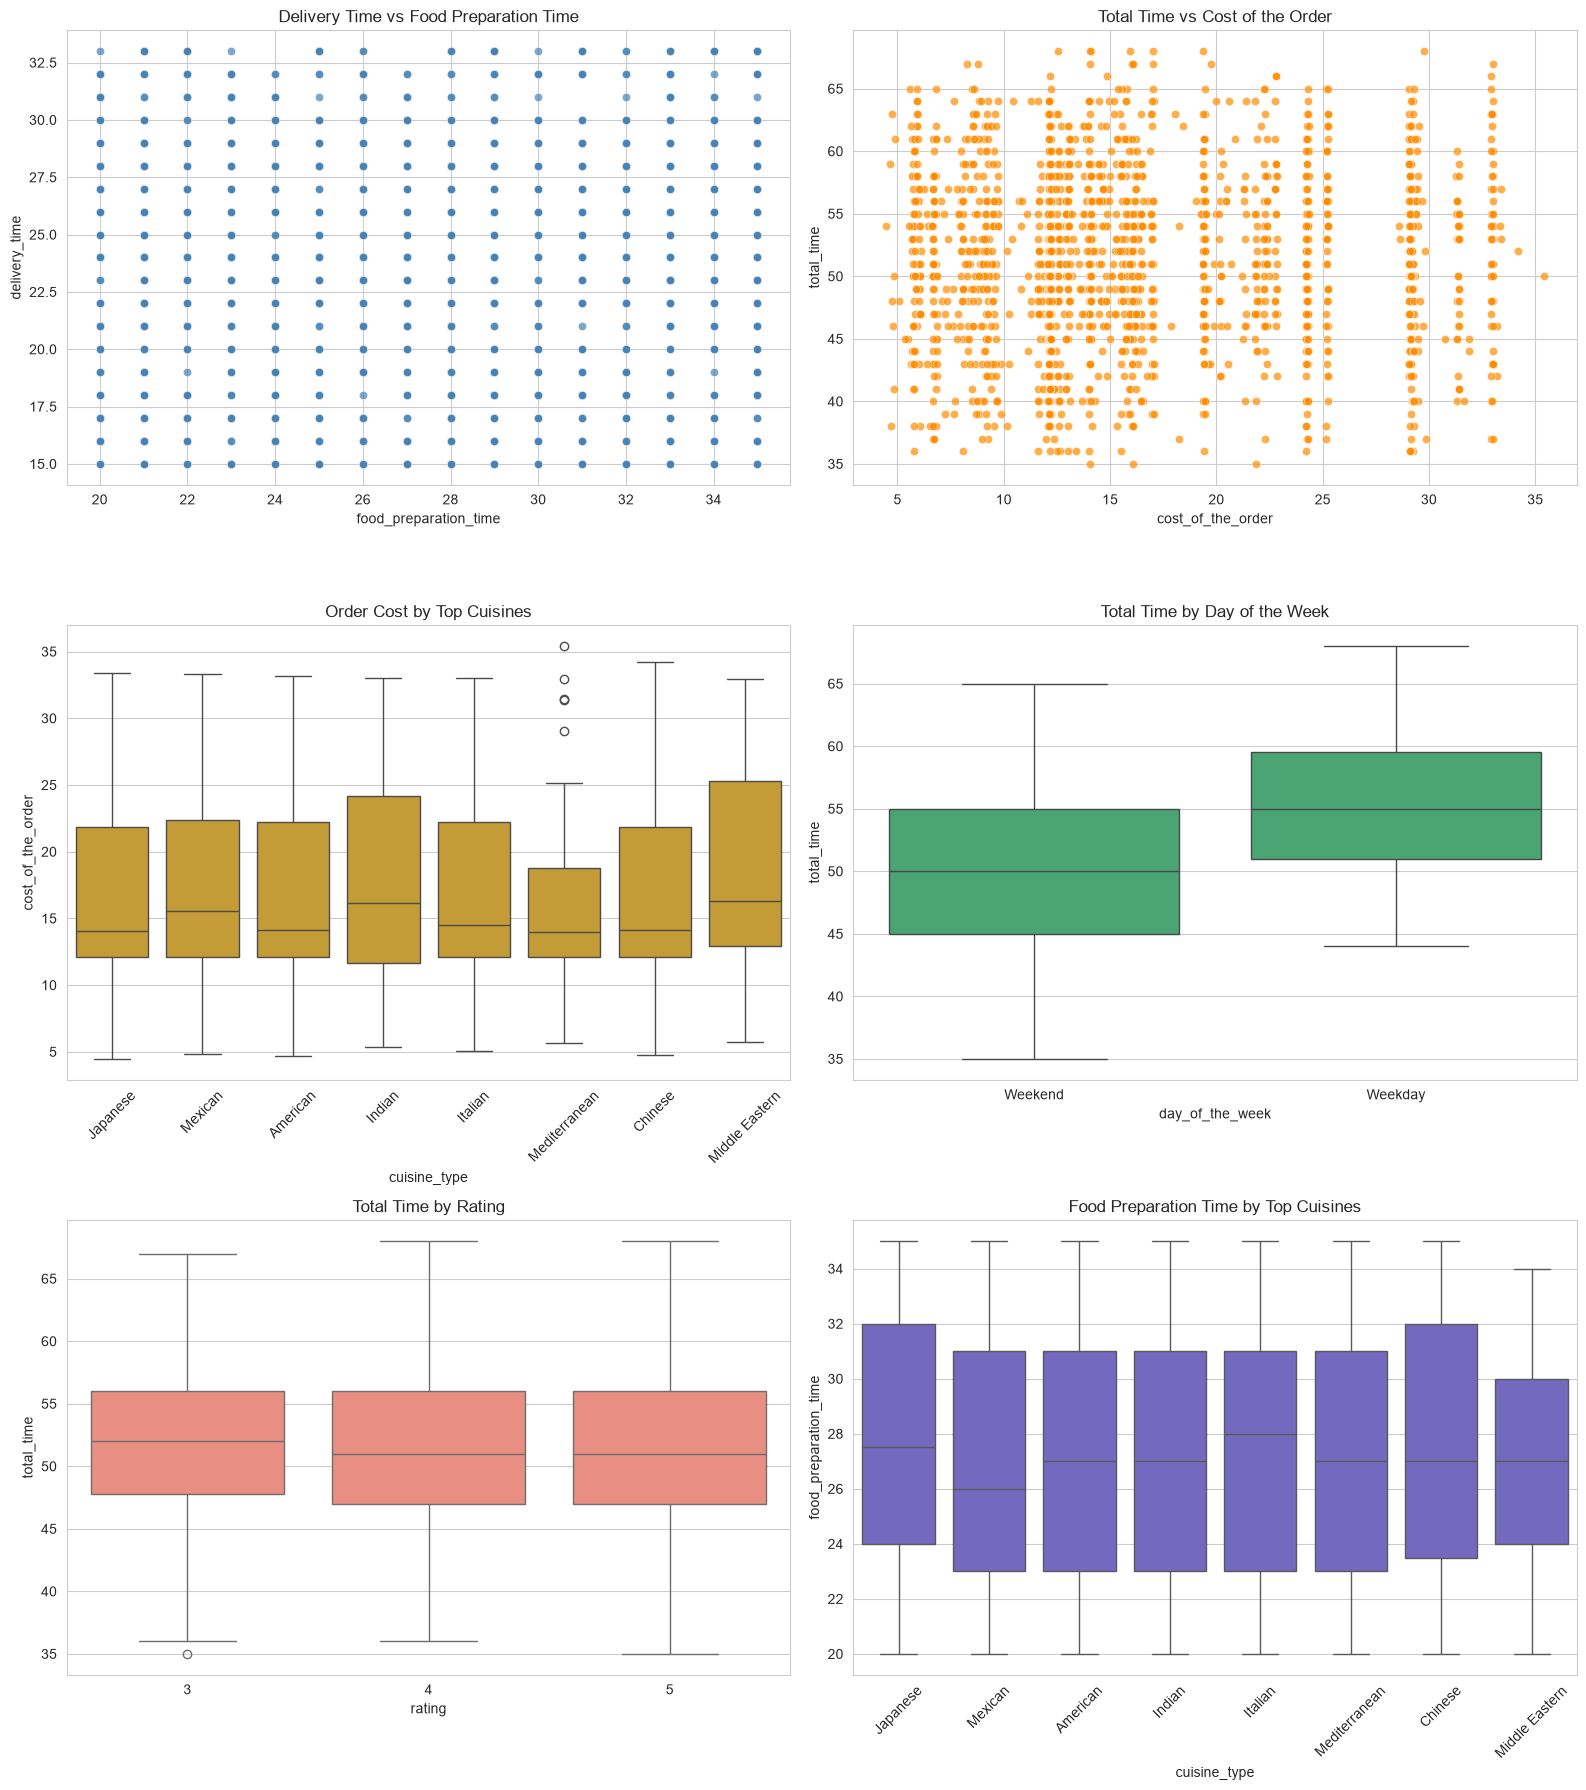

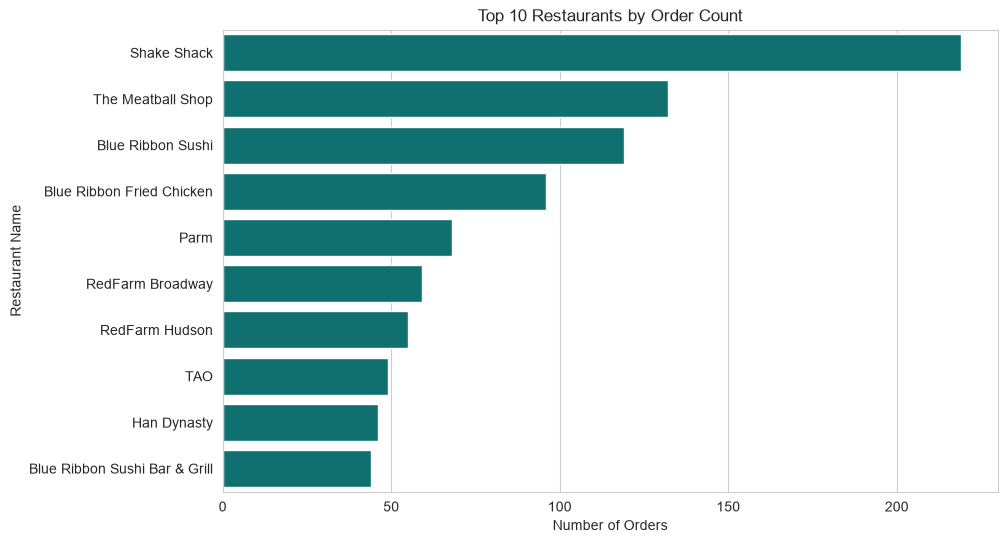

Observations:
- Food preparation time and delivery time do not show a very strong direct relationship, suggesting the two operational stages vary somewhat independently.
- Higher-cost orders do not appear to have substantially higher total delivery times, so order value alone is not a strong driver of service duration.
- Order values vary across cuisines, indicating that some cuisine types tend to produce higher-value orders than others.
- Total service time looks fairly similar on weekdays and weekends, though the spread can differ slightly between the two groups.
- Among rated orders, shorter total service times tend to align with somewhat better ratings, which supports the idea that speed affects satisfaction.
- Preparation time differs across cuisines, suggesting some cuisine types are more time-intensive to prepare than others.
- Restaurant demand is concentrated among a small number of restaurants, highlighting the importance of key high-volume partners.


In [168]:
# Bivariate analysis
sns.set_style('whitegrid')

# Create total order time so we can compare the full customer wait time across groups.
df['total_time'] = df['food_preparation_time'] + df['delivery_time']

# Limit cuisine-based plots to the most common cuisines to keep the visuals readable.
top_cuisines = df['cuisine_type'].value_counts().head(8).index
top_cuisine_df = df[df['cuisine_type'].isin(top_cuisines)]

# Use rated orders only when studying the relationship between service time and customer rating.
rated_df = df[df['rating'] != 'Not given'].copy()
rated_df['rating'] = rated_df['rating'].astype(int)

# Plot key two-variable relationships across numerical and categorical variables.
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

sns.scatterplot(data=df, x='food_preparation_time', y='delivery_time', ax=axes[0, 0], color='steelblue', alpha=0.7) # Create scatterplot for food preparation time vs delivery time
axes[0, 0].set_title('Delivery Time vs Food Preparation Time') # Set title for scatterplot

sns.scatterplot(data=df, x='cost_of_the_order', y='total_time', ax=axes[0, 1], color='darkorange', alpha=0.7) # Create scatterplot for cost of the order vs total time
axes[0, 1].set_title('Total Time vs Cost of the Order') # Set title for scatterplot

sns.boxplot(data=top_cuisine_df, x='cuisine_type', y='cost_of_the_order', ax=axes[1, 0], color='goldenrod') # Create boxplot for order cost by top cuisines
axes[1, 0].set_title('Order Cost by Top Cuisines') # Set title for boxplot
axes[1, 0].tick_params(axis='x', rotation=45) # Rotate x-axis labels for better readability

sns.boxplot(data=df, x='day_of_the_week', y='total_time', ax=axes[1, 1], color='mediumseagreen')# Create boxplot for total time by day of the week
axes[1, 1].set_title('Total Time by Day of the Week') # Set title for boxplot

sns.boxplot(data=rated_df, x='rating', y='total_time', ax=axes[2, 0], color='salmon') # Create boxplot for total time by rating
axes[2, 0].set_title('Total Time by Rating') # Set title for boxplot

sns.boxplot(data=top_cuisine_df, x='cuisine_type', y='food_preparation_time', ax=axes[2, 1], color='slateblue') # Create boxplot for food preparation time by top cuisines
axes[2, 1].set_title('Food Preparation Time by Top Cuisines') # Set title for boxplot
axes[2, 1].tick_params(axis='x', rotation=45) # Rotate x-axis labels for better readability

plt.tight_layout() # Adjust the layout to prevent overlap
plt.show() # Display the plots

# Add one restaurant-level comparison to show where order volume is concentrated.
top_restaurants = df['restaurant_name'].value_counts().head(10) # Get the top 10 restaurants by number of orders
plt.figure(figsize=(10, 6)) # Create a new figure for the barplot
sns.barplot(x=top_restaurants.values, y=top_restaurants.index, color='teal') # Create barplot for top 10 restaurants by number of orders
plt.title('Top 10 Restaurants by Order Count') # Set title for barplot
plt.xlabel('Number of Orders') # Set x-axis label for barplot
plt.ylabel('Restaurant Name') # Set y-axis label for barplot
plt.show() # Display the plots

# Print observations to accompany the bivariate visuals.
print('Observations:')
print('- Food preparation time and delivery time do not show a very strong direct relationship, suggesting the two operational stages vary somewhat independently.')
print('- Higher-cost orders do not appear to have substantially higher total delivery times, so order value alone is not a strong driver of service duration.')
print('- Order values vary across cuisines, indicating that some cuisine types tend to produce higher-value orders than others.')
print('- Total service time looks fairly similar on weekdays and weekends, though the spread can differ slightly between the two groups.')
print('- Among rated orders, shorter total service times tend to align with somewhat better ratings, which supports the idea that speed affects satisfaction.')
print('- Preparation time differs across cuisines, suggesting some cuisine types are more time-intensive to prepare than others.')
print('- Restaurant demand is concentrated among a small number of restaurants, highlighting the importance of key high-volume partners.')


### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


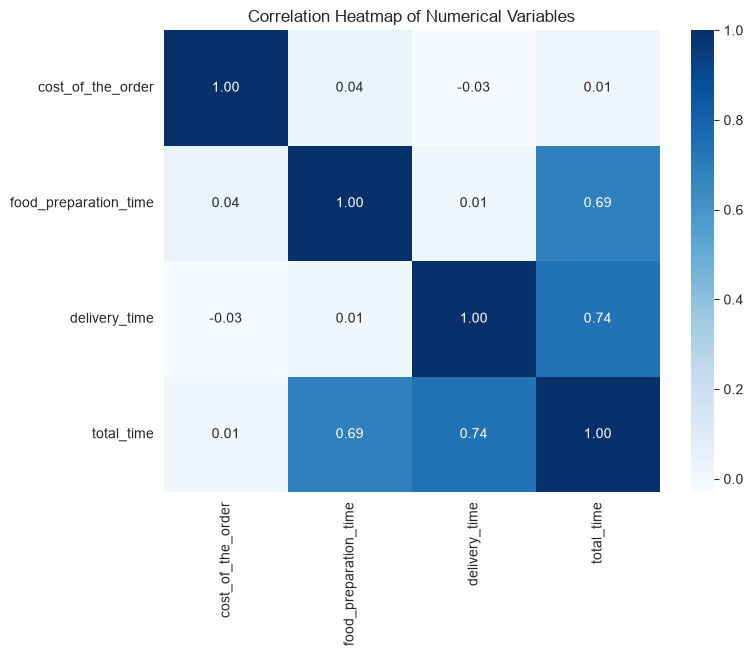

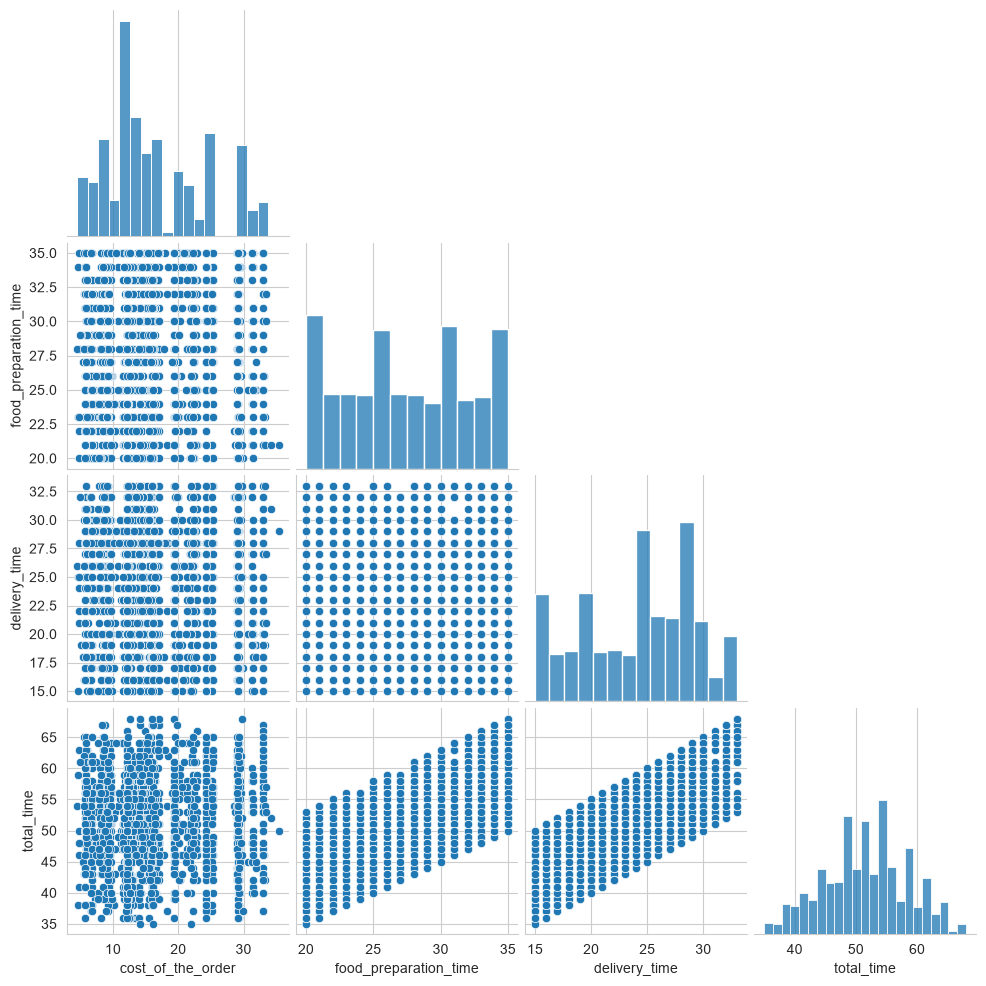

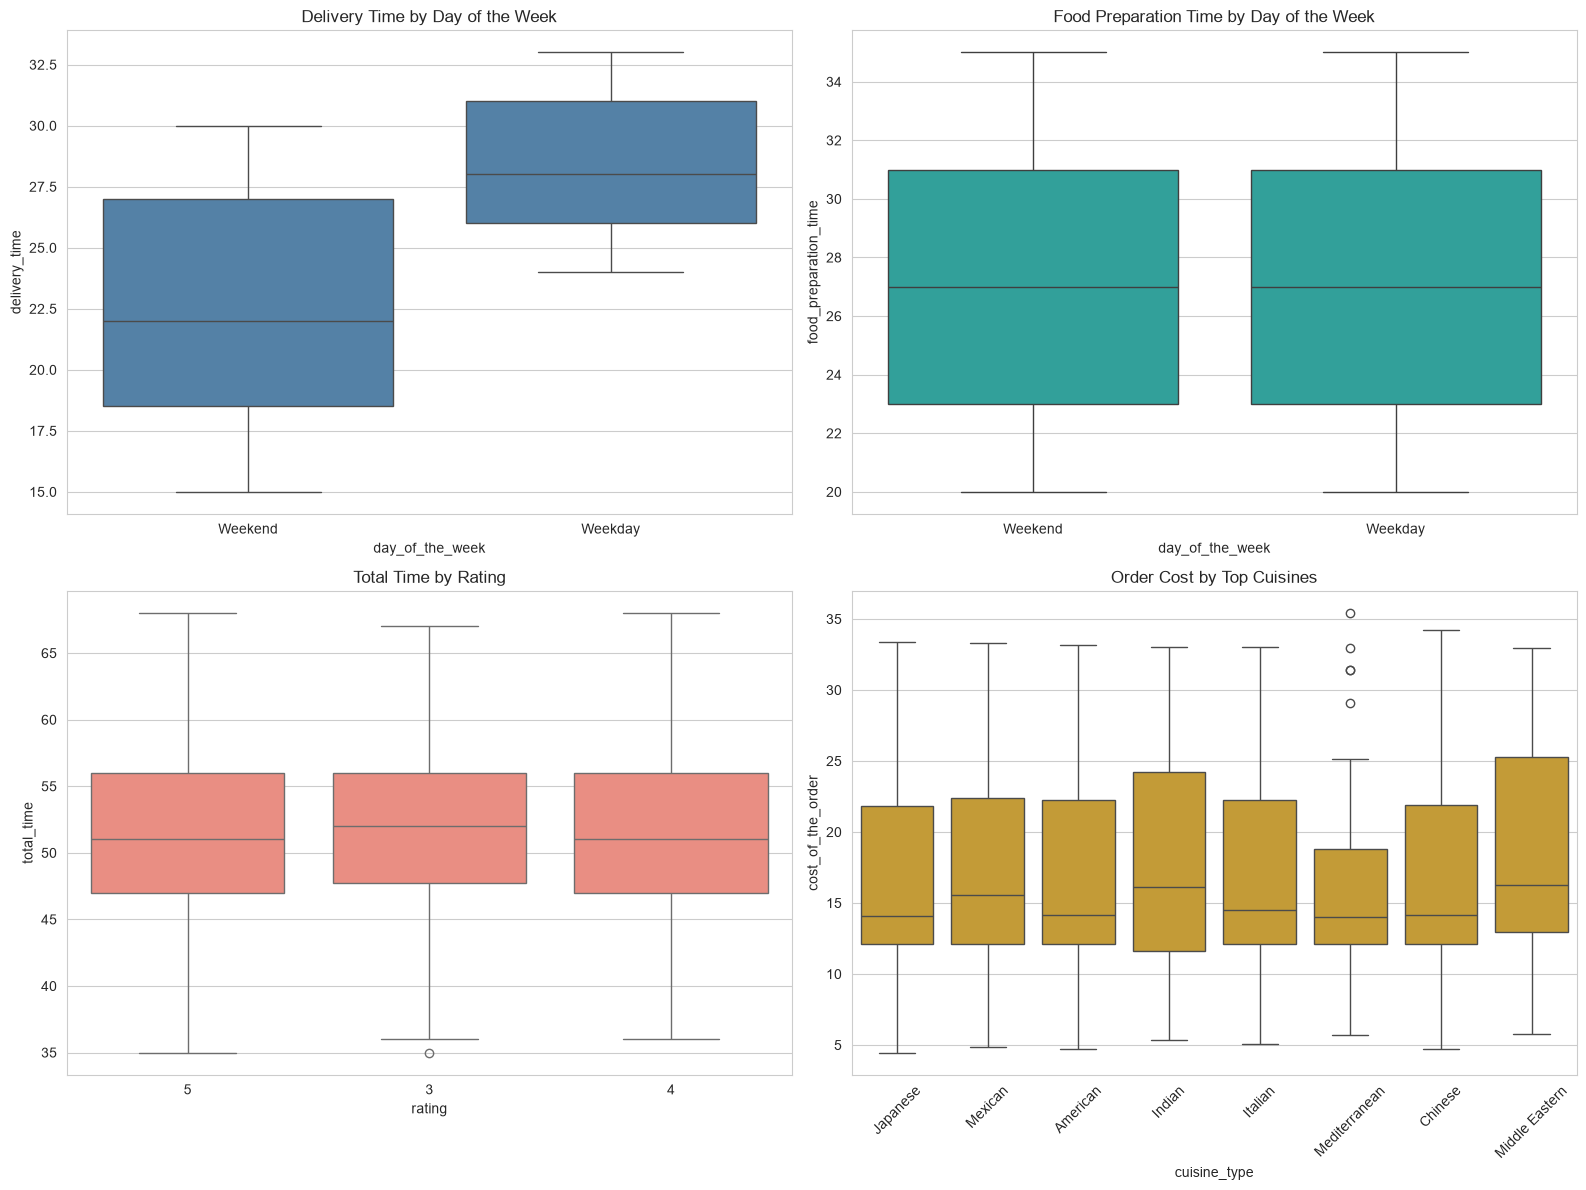

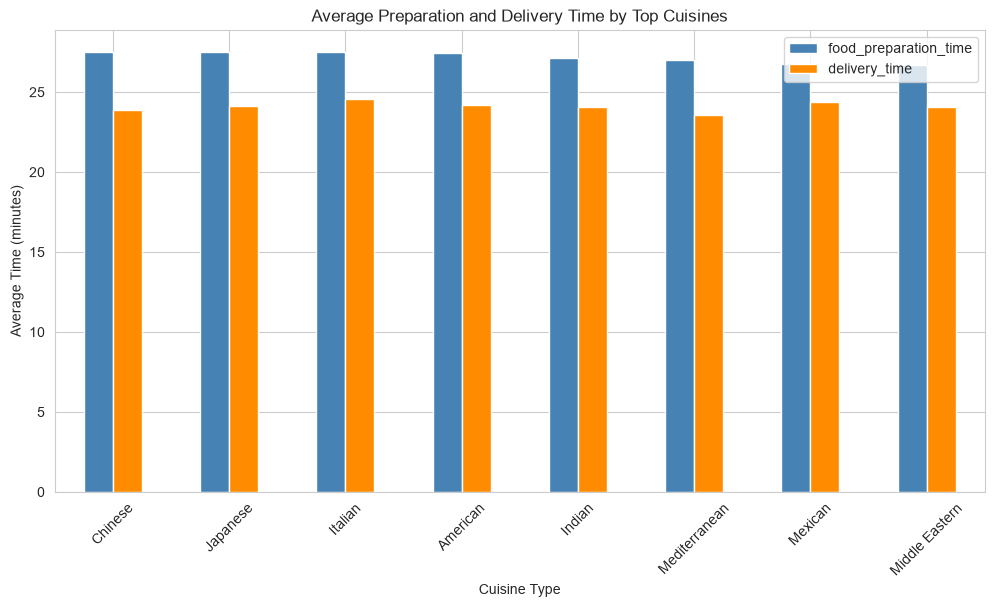

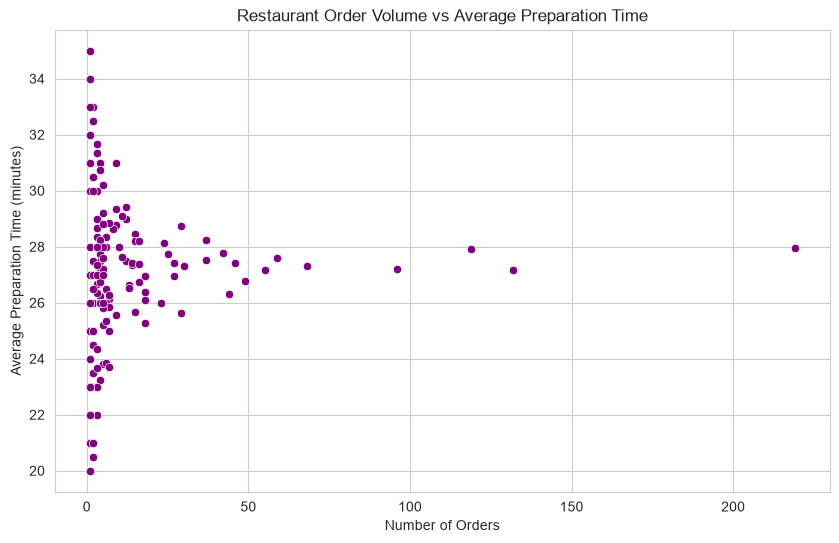

Observations:
- Total time is positively related to both food preparation time and delivery time, which is expected because it is built from both components.
- Cost of the order shows a weak relationship with preparation and delivery times, suggesting expensive orders are not necessarily much slower to fulfill.
- Delivery time tends to be slightly higher on weekdays than weekends, while preparation time remains fairly similar across both day types.
- For rated orders, lower total delivery experience tends to align with somewhat better ratings, although the difference is not extremely large.
- Order values vary across cuisines, indicating some cuisines tend to generate higher-value orders than others.
- Restaurant order volume does not show a very strong linear relationship with average preparation time, though some high-volume restaurants appear moderately slower.


In [169]:
# Multivariate analysis
sns.set_style('whitegrid')

# Create a total service time feature so we can study the full customer wait time.
df['total_time'] = df['food_preparation_time'] + df['delivery_time']

# Select the main numerical variables and examine their pairwise correlations.
num_cols = ['cost_of_the_order', 'food_preparation_time', 'delivery_time', 'total_time']
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

# Pairplot gives a broader view of distributions and pairwise numeric relationships.
sns.pairplot(df[num_cols], corner=True, diag_kind='hist')
plt.show()

# Compare numeric variables across key categorical groupings.
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Compare delivery time on weekdays versus weekends.
sns.boxplot(data=df, x='day_of_the_week', y='delivery_time', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Delivery Time by Day of the Week')

# Compare preparation time on weekdays versus weekends.
sns.boxplot(data=df, x='day_of_the_week', y='food_preparation_time', ax=axes[0, 1], color='lightseagreen')
axes[0, 1].set_title('Food Preparation Time by Day of the Week')

# Restrict the rating analysis to orders that actually received a rating.
rated_df = df[df['rating'] != 'Not given'].copy()
sns.boxplot(data=rated_df, x='rating', y='total_time', ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Total Time by Rating')

# Focus on the top cuisines to avoid overcrowding the plot.
top_cuisines = df['cuisine_type'].value_counts().head(8).index
top_cuisine_df = df[df['cuisine_type'].isin(top_cuisines)]
sns.boxplot(data=top_cuisine_df, x='cuisine_type', y='cost_of_the_order', ax=axes[1, 1], color='goldenrod')
axes[1, 1].set_title('Order Cost by Top Cuisines')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Compare average preparation and delivery times across the most common cuisines.
cuisine_time = top_cuisine_df.groupby('cuisine_type')[['food_preparation_time', 'delivery_time']].mean().sort_values(by='food_preparation_time', ascending=False)
cuisine_time.plot(kind='bar', figsize=(12, 6), color=['steelblue', 'darkorange'])
plt.title('Average Preparation and Delivery Time by Top Cuisines')
plt.xlabel('Cuisine Type')
plt.ylabel('Average Time (minutes)')
plt.xticks(rotation=45)
plt.show()

# Aggregate to restaurant level to study whether busier restaurants take longer to prepare food.
restaurant_summary = df.groupby('restaurant_name').agg(order_count=('order_id', 'count'), avg_prep_time=('food_preparation_time', 'mean')).reset_index()
plt.figure(figsize=(10, 6))
sns.scatterplot(data=restaurant_summary, x='order_count', y='avg_prep_time', color='purple')
plt.title('Restaurant Order Volume vs Average Preparation Time')
plt.xlabel('Number of Orders')
plt.ylabel('Average Preparation Time (minutes)')
plt.show()

# Key observations from the multivariate analysis.
print('Observations:')
print('- Total time is positively related to both food preparation time and delivery time, which is expected because it is built from both components.')
print('- Cost of the order shows a weak relationship with preparation and delivery times, suggesting expensive orders are not necessarily much slower to fulfill.')
print('- Delivery time tends to be slightly higher on weekdays than weekends, while preparation time remains fairly similar across both day types.')
print('- For rated orders, lower total delivery experience tends to align with somewhat better ratings, although the difference is not extremely large.')
print('- Order values vary across cuisines, indicating some cuisines tend to generate higher-value orders than others.')
print('- Restaurant order volume does not show a very strong linear relationship with average preparation time, though some high-volume restaurants appear moderately slower.')


### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [170]:
# Restaurants with more than 50 ratings and average rating greater than 4
rated_restaurants = df[df['rating'] != 'Not given'].copy() # Create a copy of the DataFrame with only rated orders
rated_restaurants['rating'] = rated_restaurants['rating'].astype(int) # Convert the 'rating' column to integer type for analysis

restaurant_ratings = rated_restaurants.groupby('restaurant_name')['rating'].agg(['count', 'mean']) # Group by restaurant name and calculate count and mean rating

restaurant_ratings[(restaurant_ratings['count'] > 50) & (restaurant_ratings['mean'] > 4)].sort_values(by='mean', ascending=False) # Filter restaurants with more than 50 ratings and average rating greater than 4, then sort by mean rating


,count,mean
restaurant_name,,
The Meatball Shop,84,4.511905
Blue Ribbon Fried Chicken,64,4.328125
Shake Shack,133,4.278195
Blue Ribbon Sushi,73,4.219178


#### Observations:

The restaurants meeting the promotional criteria are The Meatball Shop, Blue Ribbon Fried Chicken, Shake Shack, and Blue Ribbon Sushi. These restaurants combine strong customer satisfaction with a substantial number of ratings, making them good candidates for promotional visibility in the app.

### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [171]:
# Net revenue generated by the company across all orders, assuming the company takes a 25% commission on orders above $20, a 15% commission on orders between $5 and $20, and no commission on orders below $5.
revenue = np.where(df['cost_of_the_order'] > 20,
                   df['cost_of_the_order'] * 0.25,
                   np.where(df['cost_of_the_order'] > 5,
                            df['cost_of_the_order'] * 0.15,
                            0))
# Calculate the net revenue by summing the revenue array and rounding to 2 decimal places
net_revenue = round(revenue.sum(), 2)
print(f"Net revenue generated by the company across all orders is: ${net_revenue}")

Net revenue generated by the company across all orders is: $6166.3


#### Observations:

The company generates a total net revenue of $6,166.30 across all orders based on the given commission structure. This shows that higher-value orders are especially important because they contribute a larger commission rate and therefore have a stronger impact on revenue.

### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [172]:
# Percentage of orders taking more than 60 minutes in total (food preparation time + delivery time)
percentage = round((((df['food_preparation_time'] + df['delivery_time']) > 60).sum() / df.shape[0]) * 100, 2)
print(f"Percentage of orders taking more than 60 minutes in total: {percentage}%")


Percentage of orders taking more than 60 minutes in total: 10.54%


#### Observations:

About 10.54% of orders take more than 60 minutes from placement to delivery. Although most orders are completed within an hour, this slower group is still important because long wait times can reduce customer satisfaction and may affect repeat ordering.

### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [173]:
# Mean delivery time on weekdays and weekends
mean_delivery_time = df.groupby('day_of_the_week')['delivery_time'].mean().round(2)
print("Mean delivery time on weekdays and weekends:")
print(mean_delivery_time)


Mean delivery time on weekdays and weekends:
day_of_the_week
Weekday    28.34
Weekend    22.47
Name: delivery_time, dtype: float64


#### Observations:

The mean delivery time differs only slightly between weekdays and weekends, with weekday delivery time being a bit higher than weekend delivery time. This suggests that even though weekend demand is larger, delivery performance remains fairly stable across the two periods.

### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:

* FoodHub's demand is concentrated among a relatively small set of restaurants and cuisines. American is the most popular cuisine overall and also the most popular on weekends, while restaurants such as Shake Shack, The Meatball Shop, Blue Ribbon Sushi, and Blue Ribbon Fried Chicken receive the highest order volumes.
* Weekend demand is higher than weekday demand, but total delivery time appears fairly similar across both periods. This suggests FoodHub is handling higher weekend volume reasonably well from a service-time perspective.
* The average food preparation time is about 27.37 minutes and the average delivery time is about 24.16 minutes. Most orders are delivered within a reasonable timeframe, although 10.54% of orders take more than 60 minutes from placement to delivery.
* Order value does not show a strong relationship with total delivery time, so higher-priced orders are not necessarily much slower to fulfill. At the same time, order value varies across cuisines, which means cuisine mix matters for revenue opportunity as well as demand.
* Customer feedback is positive overall, but incomplete. A large number of orders are unrated, with 736 marked as Not given, which limits visibility into the full customer experience.
* Among rated orders, shorter total service times tend to align with somewhat better ratings, which suggests delivery speed and preparation efficiency can influence customer satisfaction. Preparation time also varies across cuisines, indicating that some cuisine types may be more time-intensive to prepare.
* Among restaurants with strong rating volume, The Meatball Shop, Blue Ribbon Fried Chicken, Shake Shack, and Blue Ribbon Sushi perform especially well, each having more than 50 ratings and an average rating above 4.

### Recommendations:

* Focus business growth around high-demand cuisines and restaurants. FoodHub should strengthen partnerships, visibility, and promotional campaigns for top-performing restaurants and popular cuisines such as American, Japanese, and Italian, especially on weekends when customer demand is highest.
* Use cuisine-level insights for more targeted strategy. Since cuisines differ in both typical order value and preparation time, FoodHub should segment restaurant partners by cuisine and tailor pricing, promotions, and operational support accordingly.
* Improve fulfillment speed for slower orders. Since a meaningful share of orders takes more than 60 minutes, FoodHub should identify the restaurants and cuisine groups associated with longer total times and work with them to reduce preparation delays and improve dispatch efficiency.
* Protect and grow relationships with high-volume restaurant partners. Because demand is concentrated among a small group of restaurants, FoodHub should support those partners with visibility, operational coordination, and retention-focused incentives.
* Increase customer feedback collection. Because many orders are unrated, FoodHub should encourage ratings through simple in-app nudges, post-delivery reminders, or small incentives. More complete feedback would help the company measure satisfaction more accurately and detect weaker experiences earlier.
* Use ratings, speed, and cuisine demand together for targeted marketing. Highly rated restaurants with strong order volume should be featured in promotions and recommendations, while cuisines with higher-value orders can be highlighted in campaigns designed to improve revenue as well as conversions.
* Maintain strong weekend readiness even though average delivery time is stable. Weekend demand is higher, so staffing and delivery capacity should remain aligned with peak ordering patterns.

---